In [15]:
import time
import math
import pandas as pd
import matplotlib.pyplot as plt

# Parameters
f = 2.0          # signal frequency [Hz]
dt = 0.01        # sampling step [s]
duration = 5.0   # total run time [s]

last_cross = None
prev_y = 0.0

records = []      # all samples
edges = []        # rising edges only

t0 = time.perf_counter()
steps = int(duration / dt)

for _ in range(steps):
    t = time.perf_counter() - t0

    # Simulated signal
    y = math.sin(2 * math.pi * f * t)

    # Rising edge detection
    if prev_y <= 0.0 and y > 0.0:
        if last_cross is not None:
            period = t - last_cross
            freq = 1.0 / period
        else:
            period = None
            freq = None
        last_cross = t

        edges.append({"t_s": t, "y": y, "period_s": period, "freq_hz": freq})

    records.append({"t_s": t, "y": y})
    prev_y = y
    time.sleep(dt)




In [16]:
# DataFrames
df_samples = pd.DataFrame(records)
df_edges = pd.DataFrame(edges)



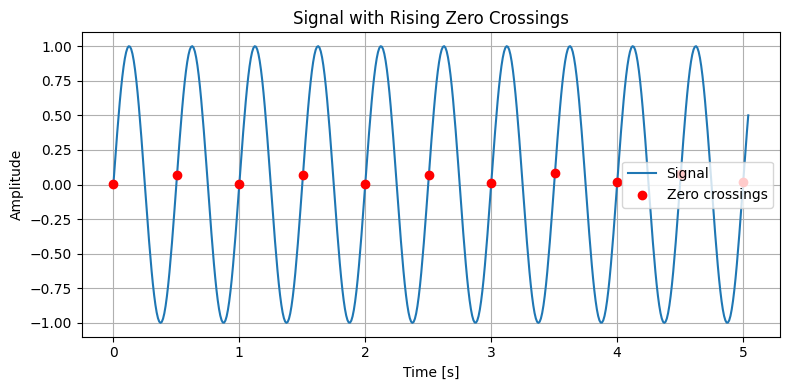

In [17]:
# --- Plot ---
plt.figure(figsize=(8,4))
plt.plot(df_samples["t_s"], df_samples["y"], label="Signal")
if not df_edges.empty:
    plt.scatter(df_edges["t_s"], df_edges["y"], color="red", zorder=5, label="Zero crossings")

plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("Signal with Rising Zero Crossings")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()